#  *PROJECT NAME - RICE LEAF DISEASE DETECTION*



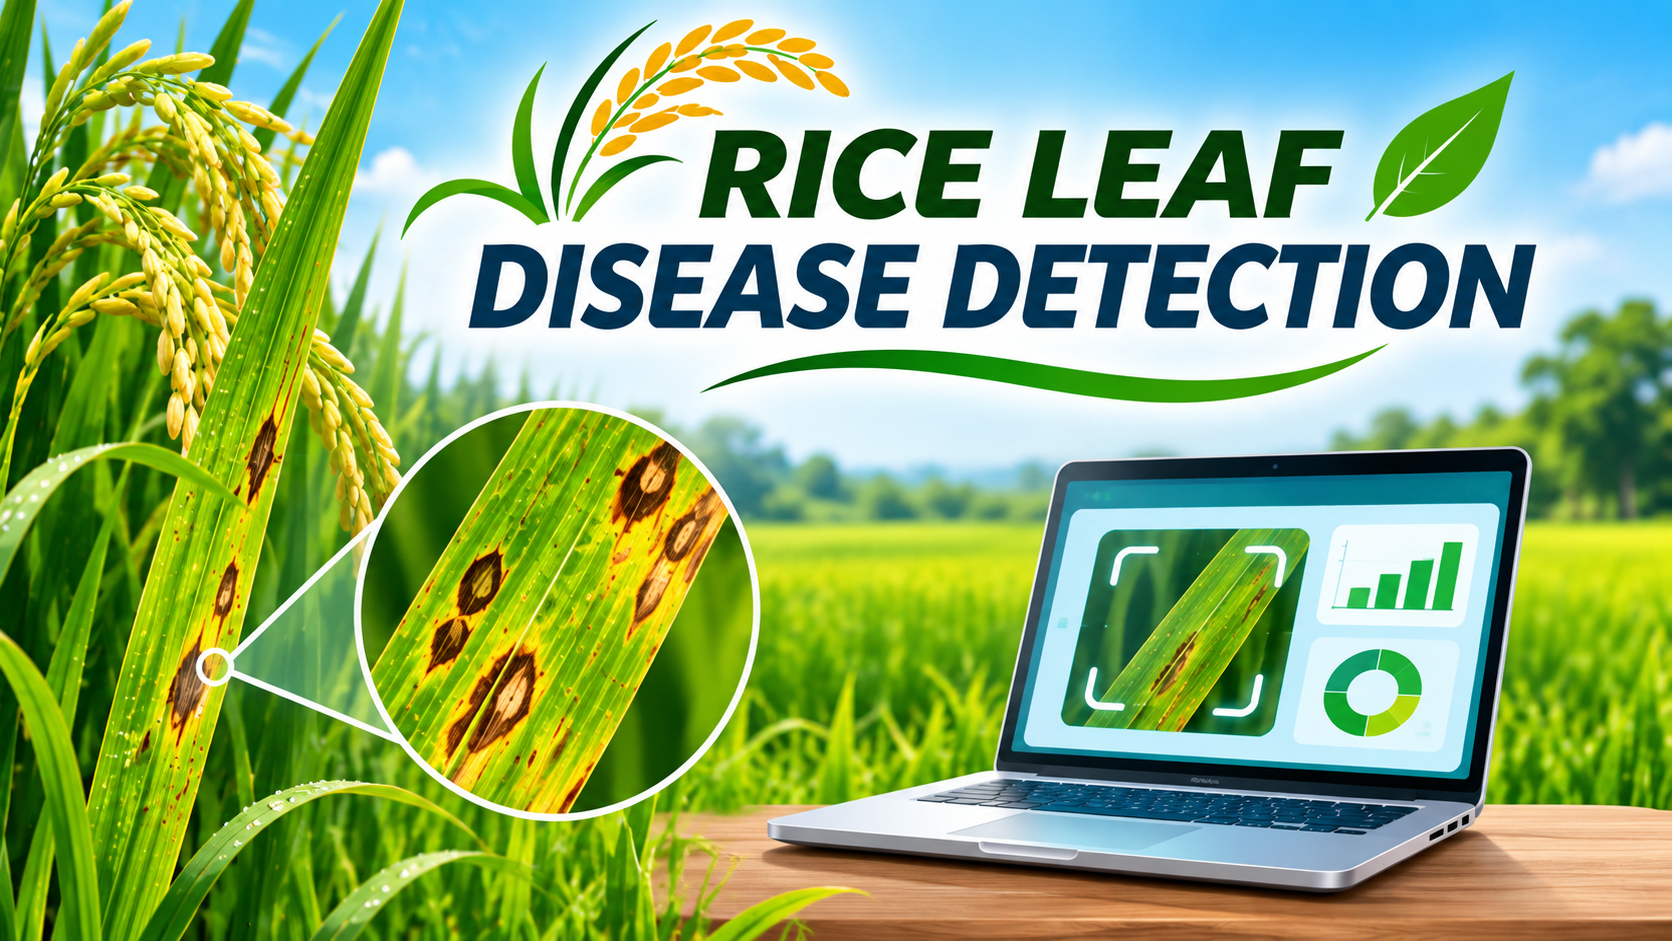

##### **Project Type**    - DEEP LEARNING  – IMAGE CLASSIFICATION
##### **Contribution**    - INDIVIDUAL
##### **Name -** SANJAYMOHAN.V


# PROJECT SUMMARY

Rice Leaf Disease Detection is a Deep Learning-based image classification project developed to identify diseases in rice plants using leaf images. The main objective of this project is to help detect rice leaf diseases at an early stage and support better crop health management.

The project uses **Convolutional Neural Network (CNN)** and **MobileNetV2**, which are deep learning models used for image classification. The dataset contains three rice leaf disease categories: Brown Spot, Leaf Smut, and Bacterial Leaf Blight.

The images undergo preprocessing techniques such as image resizing, image normalization, and data augmentation to prepare them for model training. The trained models analyze the input leaf images and classify them into the appropriate disease category.

The project is implemented using Python and TensorFlow/Keras in Google Colab. The performance of CNN and MobileNetV2 is evaluated using accuracy, classification reports, and confusion matrices. The project aims to demonstrate how deep learning and computer vision can be applied to agricultural disease detection.

# **GitHub Link -**

# Task 1: COMPLETE DATA ANALYSIS REPORT

# *INTRODUCTION*
Exploratory Data Analysis (EDA) is an important step in a machine learning project. It helps us understand the dataset, identify its structure, examine image properties, and check whether the data is suitable for model development.

In this project, EDA was performed on a rice leaf disease image dataset containing three disease categories: Brown spot, Leaf smut, and Bacterial leaf blight.

In [1]:
from google.colab import files
uploaded = files.upload()


Saving rice+leaf+diseases.zip to rice+leaf+diseases.zip


In [3]:
import tensorflow as tf
import numpy as np
import random

tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

print("Random seeds configured successfully!")

Random seeds configured successfully!


In [4]:
import zipfile
import os
zip_path = "/content/rice+leaf+diseases.zip"
extract_path = "/content/rice_dataset"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print("Dataset extracted successfully!")


Dataset extracted successfully!


In [5]:
for root, dirs, files in os.walk(extract_path):
    print("Folder:", root)
    print("Number of images:", len(files))
    print("-" * 40)


Folder: /content/rice_dataset
Number of images: 0
----------------------------------------
Folder: /content/rice_dataset/Brown spot
Number of images: 40
----------------------------------------
Folder: /content/rice_dataset/Leaf smut
Number of images: 40
----------------------------------------
Folder: /content/rice_dataset/Bacterial leaf blight
Number of images: 40
----------------------------------------


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from PIL import Image


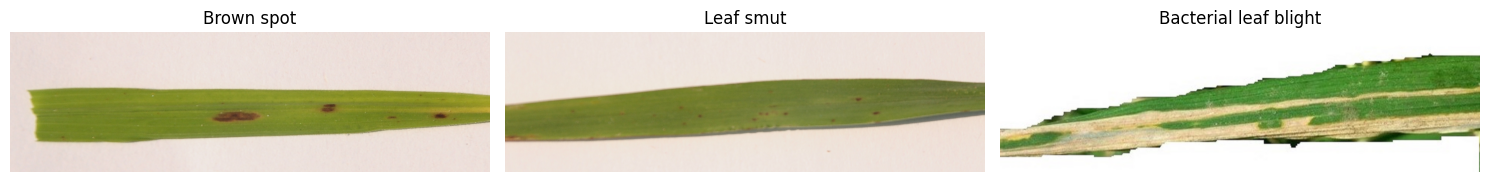

In [9]:

class_names = [
    "Brown spot",
    "Leaf smut",
    "Bacterial leaf blight"
]

plt.figure(figsize=(15,5))
for i, class_name in enumerate(class_names):
    folder_path = os.path.join(extract_path, class_name)
    image_files = os.listdir(folder_path)
    image_path = os.path.join(folder_path, image_files[0])
    img = Image.open(image_path)
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")
plt.tight_layout()
plt.show()


In [10]:
image_data = []
for class_name in class_names:
    folder_path = os.path.join(extract_path, class_name)
    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)
        img = Image.open(image_path)
        width, height = img.size
        image_data.append({
            "Image_Name": image_name,
            "Disease": class_name,
            "Width": width,
            "Height": height,
            "Format": img.format
        })
df = pd.DataFrame(image_data)
print(df.head())




     Image_Name     Disease  Width  Height Format
0  DSC_0301.JPG  Brown spot   3081     897   JPEG
1  DSC_0112.jpg  Brown spot    427     193   JPEG
2  DSC_0114.jpg  Brown spot    296      88   JPEG
3  DSC_0104.jpg  Brown spot   1530     371   JPEG
4  DSC_0111.jpg  Brown spot    316     127   JPEG


In [11]:
print("Image dimensions summary:")
print(df[["Width", "Height"]].describe())


Image dimensions summary:
             Width       Height
count   120.000000   120.000000
mean   2398.441667   721.341667
std    1130.488894   344.262273
min     250.000000    71.000000
25%    1137.000000   380.000000
50%    3081.000000   897.000000
75%    3081.000000   897.000000
max    4160.000000  2340.000000


In [12]:
print("Image formats:")
print(df["Format"].value_counts())


Image formats:
Format
JPEG    120
Name: count, dtype: int64


In [13]:
print("Disease folders:", class_names)
for class_name in class_names:
    folder_path = os.path.join(extract_path, class_name)
    image_files = os.listdir(folder_path)
    print(class_name, ":", len(image_files), "images")


Disease folders: ['Brown spot', 'Leaf smut', 'Bacterial leaf blight']
Brown spot : 40 images
Leaf smut : 40 images
Bacterial leaf blight : 40 images


In [14]:

image_data = []
for class_name in class_names:
    folder_path = os.path.join(extract_path, class_name)
    for image_name in os.listdir(folder_path):
        if image_name.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(folder_path, image_name)
            with Image.open(image_path) as img:
                width, height = img.size
                image_data.append({
                    "Image_Name": image_name,
                    "Disease": class_name,
                    "Width": width,
                    "Height": height,
                    "Format": img.format
                })
df = pd.DataFrame(image_data)
print("Total images:", len(df))
print("\nDisease-wise image count:")
print(df["Disease"].value_counts())


Total images: 120

Disease-wise image count:
Disease
Brown spot               40
Leaf smut                40
Bacterial leaf blight    40
Name: count, dtype: int64


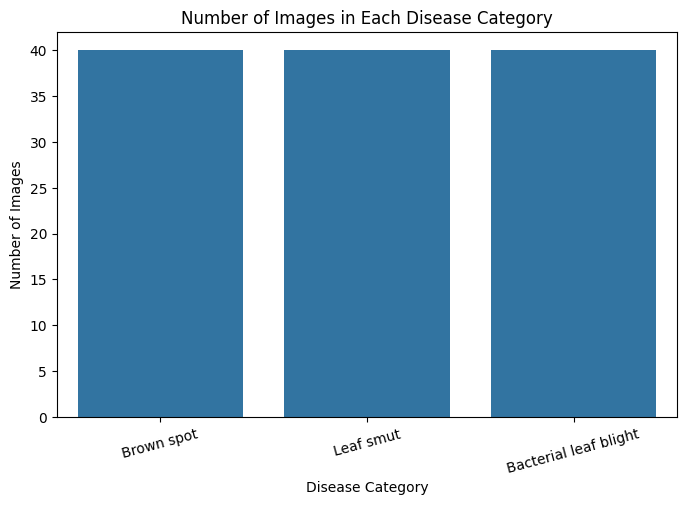

In [15]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x="Disease",
   order=class_names
)
plt.title("Number of Images in Each Disease Category")
plt.xlabel("Disease Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.show()


In [16]:
print(df.groupby("Disease")[["Width", "Height"]].describe())


                      Width                                                  \
                      count      mean          std     min      25%     50%   
Disease                                                                       
Bacterial leaf blight  40.0  3081.000     0.000000  3081.0  3081.00  3081.0   
Brown spot             40.0  1951.275  1237.348488   286.0   678.50  3081.0   
Leaf smut              40.0  2163.050  1276.235107   250.0   601.75  3081.0   

                                      Height                              \
                          75%     max  count     mean         std    min   
Disease                                                                    
Bacterial leaf blight  3081.0  3081.0   40.0  897.000    0.000000  897.0   
Brown spot             3081.0  3081.0   40.0  589.175  352.656286   88.0   
Leaf smut              3081.0  4160.0   40.0  677.850  430.996374   71.0   

                                                     
              

In [17]:
print("Image Dimensions:")
print(df.groupby("Disease")[["Width", "Height"]].describe())

Image Dimensions:
                      Width                                                  \
                      count      mean          std     min      25%     50%   
Disease                                                                       
Bacterial leaf blight  40.0  3081.000     0.000000  3081.0  3081.00  3081.0   
Brown spot             40.0  1951.275  1237.348488   286.0   678.50  3081.0   
Leaf smut              40.0  2163.050  1276.235107   250.0   601.75  3081.0   

                                      Height                              \
                          75%     max  count     mean         std    min   
Disease                                                                    
Bacterial leaf blight  3081.0  3081.0   40.0  897.000    0.000000  897.0   
Brown spot             3081.0  3081.0   40.0  589.175  352.656286   88.0   
Leaf smut              3081.0  4160.0   40.0  677.850  430.996374   71.0   

                                                  

In [18]:
image_path = os.path.join(
    extract_path,
    "Brown spot",
    os.listdir(os.path.join(extract_path, "Brown spot"))[0]
)
img = Image.open(image_path).convert("RGB")
img_array = np.array(img)
print("Image shape:", img_array.shape)
print("Data type:", img_array.dtype)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())


Image shape: (897, 3081, 3)
Data type: uint8
Minimum pixel value: 1
Maximum pixel value: 245


# RICE LEAF DISEASE DETECTION
## Task 1: Complete Data Analysis Report


### 1.1. Dataset Description

The dataset contains images of rice leaves belonging to three disease categories.

| Disease category | Number of images |
|---|---:|
| Brown spot | 40 |
| Leaf smut | 40 |
| Bacterial leaf blight | 40 |
| **Total** | **120** |

The dataset contains 120 images, with 40 images in each category.

### 1.2 Dataset Extraction and Folder Inspection

The dataset was downloaded as a ZIP file and extracted using Python's `zipfile` library.

The `os` library was used to inspect the extracted folders and count the number of files in each disease category.

This step helped verify the dataset folder structure and the availability of image files.

### 1.3 Image Visualization

Sample images from all three disease categories were displayed using Matplotlib and PIL.

The visualization helped examine the appearance of rice leaves and observe visible differences between the disease categories.

### 1.4 Image Information Analysis

A Pandas DataFrame was created to store information about the images.

The following attributes were collected:

- Image name
- Disease category
- Image width
- Image height
- Image format

This information helped understand the structure and properties of the image dataset.

### 1.5 Image Dimensions Analysis

The width and height of the images were examined using Pandas descriptive statistics.

The analysis showed that the original images had different dimensions. Therefore, image resizing was required before model training.

The image dimensions were examined using:

`df[["Width", "Height"]].describe()`

### 1.6 Image Format Analysis

The image formats were examined using the Pandas `value_counts()` function.

This helped identify the different file formats available in the dataset.

### 1.7 Disease-wise Image Distribution

The number of images in each disease category was calculated and visualized using a bar chart.

The dataset contains:

- Brown spot: 40 images
- Leaf smut: 40 images
- Bacterial leaf blight: 40 images

The distribution is balanced because each disease category contains the same number of images.

### 1.8 Pixel Value Analysis

One sample image from the Brown spot category was converted into RGB format and then into a NumPy array.

The following properties were examined:

- Image shape
- Data type
- Minimum pixel value
- Maximum pixel value

The image pixel data was stored in the `uint8` data type, with pixel values ranging from 0 to 255.

### 1.9 Libraries Used

The following Python libraries were used during the EDA process:

| Library | Purpose |
|---|---|
| NumPy | Image array and numerical operations |
| Pandas | Dataset information and analysis |
| Matplotlib | Image visualization and plotting |
| Seaborn | Statistical visualization |
| OS | Folder and file operations |
| PIL (Pillow) | Opening and inspecting images |

### 1.10 Key Findings

The following findings were obtained from the exploratory data analysis:

1. The dataset contains 120 rice leaf images.
2. There are three disease categories.
3. Each disease category contains 40 images.
4. The dataset has an equal number of images in all three categories.
5. The original images have different dimensions.
6. Image metadata such as width, height, name, and format was collected.
7. Pixel values were found to range from 0 to 255 in the examined image.

### 1.11 Conclusion

Exploratory Data Analysis was successfully performed on the rice leaf disease dataset.

The dataset contains 120 images belonging to three disease categories: Brown spot, Leaf smut, and Bacterial leaf blight.

Image visualization, image dimension analysis, format analysis, disease-wise image distribution, and pixel value analysis were performed.

The EDA results provided an understanding of the dataset and helped identify the need for image preprocessing before developing deep learning models.

Therefore, the dataset was considered ready for the next stage of the project, which involves image preprocessing and model development.


# TASK 2: RICE LEAF DISEASE CLASSIFICATION USING CNN AND MOBILENETV2


In [19]:
IMG_SIZE = 224
print("Target image size:", IMG_SIZE, "x", IMG_SIZE)

Target image size: 224 x 224


Original image size: (3081, 897)
Resized image size: (224, 224)


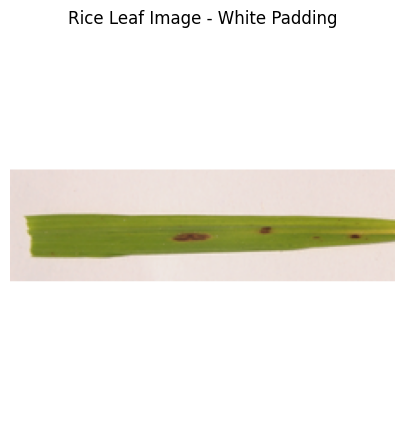

In [20]:
from PIL import ImageOps
import matplotlib.pyplot as plt
resized_img = ImageOps.pad(
    img,
    (IMG_SIZE, IMG_SIZE),
    method=Image.Resampling.LANCZOS,
    color=(255, 255, 255)
)
print("Original image size:", img.size)
print("Resized image size:", resized_img.size)
plt.figure(figsize=(5, 5))
plt.imshow(resized_img)
plt.title("Rice Leaf Image - White Padding")
plt.axis("off")
plt.show()

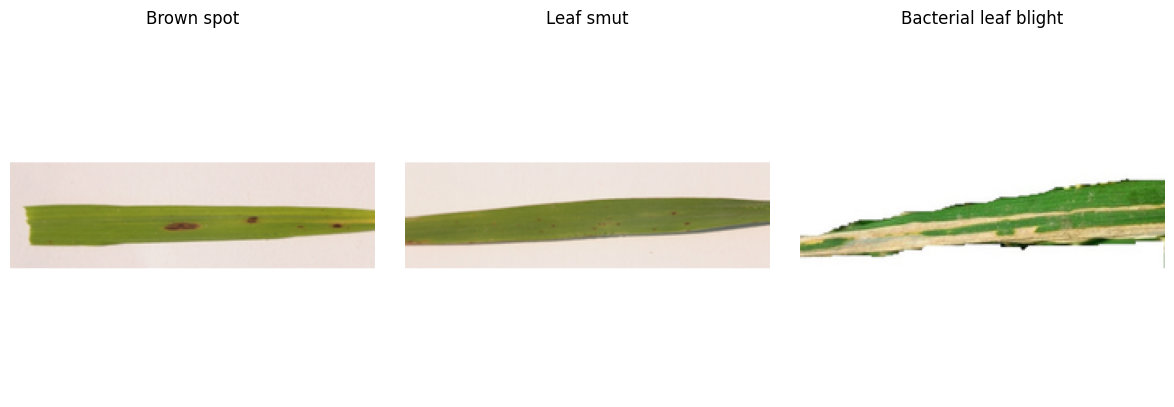

In [21]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import os
dataset_path = "/content/rice_dataset"
class_names = [
    "Brown spot",
    "Leaf smut",
    "Bacterial leaf blight"
]
plt.figure(figsize=(12, 4))
for i, class_name in enumerate(class_names):
    folder_path = os.path.join(dataset_path, class_name)
    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    image_path = os.path.join(folder_path, image_files[0])
    img = Image.open(image_path).convert("RGB")
    resized_img = ImageOps.pad(
        img,
        (224, 224),
        method=Image.Resampling.LANCZOS,
        color=(255, 255, 255)
    )
    plt.subplot(1, 3, i + 1)
    plt.imshow(resized_img)
    plt.title(class_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [22]:
import os
from PIL import Image, ImageOps
input_path = "/content/rice_dataset"
output_path = "/content/rice_processed"
IMG_SIZE = 224
for class_name in class_names:
    input_folder = os.path.join(input_path, class_name)
    output_folder = os.path.join(output_path, class_name)
    os.makedirs(output_folder, exist_ok=True)
    for image_name in os.listdir(input_folder):
        image_path = os.path.join(input_folder, image_name)
        try:
            img = Image.open(image_path).convert("RGB")
            resized_img = ImageOps.pad(
                img,
                (IMG_SIZE, IMG_SIZE),
                method=Image.Resampling.LANCZOS,
                color=(255, 255, 255)
            )
            resized_img.save(
                os.path.join(output_folder, image_name)
            )
        except Exception as e:
            print("Error:", image_name, e)
print("Image preprocessing completed!")

Image preprocessing completed!


In [23]:
import os
output_path = "/content/rice_processed"
total_images = 0
for class_name in class_names:
    folder_path = os.path.join(output_path, class_name)
    image_count = len([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    total_images += image_count
    print(class_name, ":", image_count, "images")
print("Total processed images:", total_images)

Brown spot : 40 images
Leaf smut : 40 images
Bacterial leaf blight : 40 images
Total processed images: 120


In [24]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
print("Libraries imported successfully!")

Libraries imported successfully!


In [25]:
import os
import pandas as pd
dataset_path = "/content/rice_processed"
data = []
for class_name in class_names:
    folder_path = os.path.join(dataset_path, class_name)
    for image_name in os.listdir(folder_path):
        if image_name.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(folder_path, image_name)
            data.append({
                "image_path": image_path,
                "label": class_name
            })
image_df = pd.DataFrame(data)
print(image_df.head())
print("\nTotal images:", len(image_df))

                                        image_path       label
0  /content/rice_processed/Brown spot/DSC_0301.JPG  Brown spot
1  /content/rice_processed/Brown spot/DSC_0112.jpg  Brown spot
2  /content/rice_processed/Brown spot/DSC_0114.jpg  Brown spot
3  /content/rice_processed/Brown spot/DSC_0104.jpg  Brown spot
4  /content/rice_processed/Brown spot/DSC_0111.jpg  Brown spot

Total images: 120


In [26]:
train_df, temp_df = train_test_split(
    image_df,
    test_size=0.30,
    random_state=42,
    stratify=image_df["label"]
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(train_df) + len(val_df) + len(test_df))

Training images: 84
Validation images: 18
Testing images: 18
Total images: 120


In [27]:
print("Training set distribution:")
print(train_df["label"].value_counts())

print("\nValidation set distribution:")
print(val_df["label"].value_counts())

print("\nTesting set distribution:")
print(test_df["label"].value_counts())

Training set distribution:
label
Leaf smut                28
Brown spot               28
Bacterial leaf blight    28
Name: count, dtype: int64

Validation set distribution:
label
Leaf smut                6
Brown spot               6
Bacterial leaf blight    6
Name: count, dtype: int64

Testing set distribution:
label
Leaf smut                6
Brown spot               6
Bacterial leaf blight    6
Name: count, dtype: int64


In [28]:
import numpy as np
from PIL import Image
label_mapping = {
    "Brown spot": 0,
    "Leaf smut": 1,
    "Bacterial leaf blight": 2
}
def load_images(dataframe):
    images = []
    labels = []
    for row in dataframe.itertuples():
        img = Image.open(row.image_path).convert("RGB")
        img_array = np.array(img)
        images.append(img_array)
        labels.append(label_mapping[row.label])
    return np.array(images), np.array(labels)
X_train, y_train = load_images(train_df)
X_val, y_val = load_images(val_df)
X_test, y_test = load_images(test_df)

print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Validation images shape:", X_val.shape)
print("Validation labels shape:", y_val.shape)

print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Training images shape: (84, 224, 224, 3)
Training labels shape: (84,)
Validation images shape: (18, 224, 224, 3)
Validation labels shape: (18,)
Testing images shape: (18, 224, 224, 3)
Testing labels shape: (18,)


In [29]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
print("Data type:", X_train.dtype)

Minimum pixel value: 0
Maximum pixel value: 255
Data type: uint8


In [46]:
X_train_cnn = X_train.astype("float32") / 255.0
X_val_cnn = X_val.astype("float32") / 255.0
X_test_cnn = X_test.astype("float32") / 255.0
print("Minimum pixel value:", X_train_cnn.min())
print("Maximum pixel value:", X_train_cnn.max())

print("\nTraining data shape:", X_train_cnn.shape)
print("Validation data shape:", X_val_cnn.shape)
print("Testing data shape:", X_test_cnn.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0

Training data shape: (84, 224, 224, 3)
Validation data shape: (18, 224, 224, 3)
Testing data shape: (18, 224, 224, 3)


In [47]:
from tensorflow.keras.applications.mobilenet_v2 \
 import preprocess_input
X_train_mobilenet = preprocess_input(
    X_train.astype("float32")
)
X_val_mobilenet = preprocess_input(
    X_val.astype("float32")
)
X_test_mobilenet = preprocess_input(
    X_test.astype("float32")
)
print("Minimum pixel value:", X_train_mobilenet.min())
print("Maximum pixel value:", X_train_mobilenet.max())

print("\nTraining shape:", X_train_mobilenet.shape)
print("Validation shape:", X_val_mobilenet.shape)
print("Testing shape:", X_test_mobilenet.shape)

Minimum pixel value: -1.0
Maximum pixel value: 1.0

Training shape: (84, 224, 224, 3)
Validation shape: (18, 224, 224, 3)
Testing shape: (18, 224, 224, 3)


In [56]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
cnn_model = Sequential([

    Input(shape=(224, 224, 3)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),

    Dropout(0.5),

    Dense(3, activation="softmax")
])

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("CNN model compiled successfully!")

CNN model compiled successfully!


In [58]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
history = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=25,
    batch_size=16,
    callbacks=[early_stop]
)

Epoch 1/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 127ms/step - accuracy: 0.2024 - loss: 1.1428 - val_accuracy: 0.3333 - val_loss: 1.0997
Epoch 2/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.3690 - loss: 1.1137 - val_accuracy: 0.3333 - val_loss: 1.1037
Epoch 3/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.3571 - loss: 1.1072 - val_accuracy: 0.3333 - val_loss: 1.1004
Epoch 4/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3214 - loss: 1.1048 - val_accuracy: 0.3333 - val_loss: 1.0996
Epoch 5/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.3810 - loss: 1.1001 - val_accuracy: 0.3333 - val_loss: 1.1002
Epoch 6/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3095 - loss: 1.1093 - val_accuracy: 0.3333 - val_loss: 1.0980
Epoch 7/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3333 - loss: 1.0916 - val_accuracy: 0.3333 - val_loss: 1.0950
Epoch 8/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3333 - loss: 1.0907 - val_accuracy: 0.3333 - val_loss: 1.0921

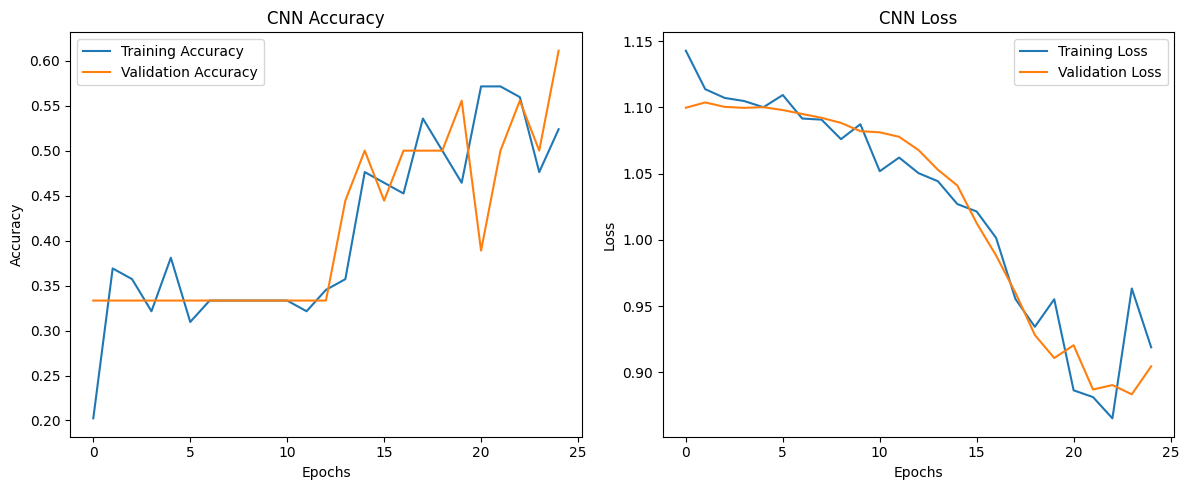

In [59]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [60]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(3, activation="softmax")(x)
mobilenet_model = Model(
    inputs=base_model.input,
    outputs=output
)
mobilenet_model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_5[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [61]:
mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("MobileNetV2 model compiled successfully!")

MobileNetV2 model compiled successfully!


In [62]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_mobilenet = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
mobilenet_history = mobilenet_model.fit(
    X_train_mobilenet,
    y_train,
    validation_data=(X_val_mobilenet, y_val),
    epochs=25,
    batch_size=16,
    callbacks=[early_stop_mobilenet]
)

Epoch 1/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 352ms/step - accuracy: 0.3690 - loss: 1.3164 - val_accuracy: 0.5556 - val_loss: 1.0212
Epoch 2/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5714 - loss: 1.0081 - val_accuracy: 0.6667 - val_loss: 0.8322
Epoch 3/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.6667 - loss: 0.8147 - val_accuracy: 0.6667 - val_loss: 0.7435
Epoch 4/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8095 - loss: 0.5981 - val_accuracy: 0.7222 - val_loss: 0.6745
Epoch 5/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 0.7857 - loss: 0.5545 - val_accuracy: 0.7222 - val_loss: 0.5920
Epoch 6/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8571 - loss: 0.4272 - val_accuracy: 0.8889 - val_loss: 0.5224
Epoch 7/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9048 - loss: 0.3459 - val_accuracy: 0.8889 - val_loss: 0.4836
Epoch 8/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.8810 - loss: 0.3727 - val_accuracy: 0.8889 - val_loss: 0.4628

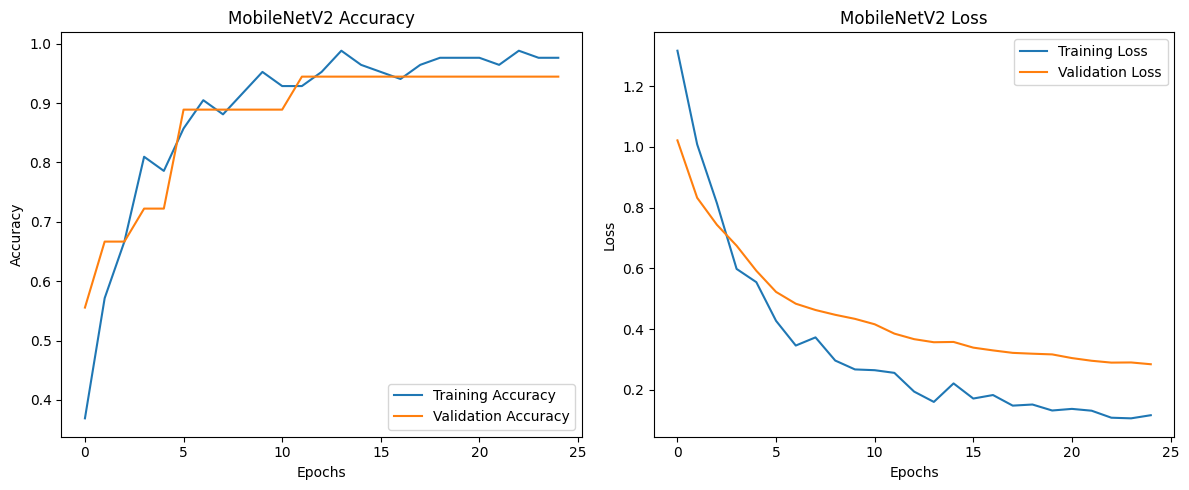

In [63]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(
    mobilenet_history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    mobilenet_history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    mobilenet_history.history["loss"],
    label="Training Loss"
)
plt.plot(
    mobilenet_history.history["val_loss"],
    label="Validation Loss"
)
plt.title("MobileNetV2 Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [64]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test
)
print("CNN Test Loss:", cnn_test_loss)
print("CNN Test Accuracy:", cnn_test_accuracy * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.6111 - loss: 0.9573
CNN Test Loss: 0.9573227763175964
CNN Test Accuracy: 61.11111044883728 %


In [65]:
mobilenet_test_loss, mobilenet_test_accuracy = mobilenet_model.evaluate(
    X_test_mobilenet,
    y_test
)
print("MobileNetV2 Test Loss:", mobilenet_test_loss)
print("MobileNetV2 Test Accuracy:", mobilenet_test_accuracy * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.8889 - loss: 0.4412
MobileNetV2 Test Loss: 0.4412165880203247
MobileNetV2 Test Accuracy: 88.88888955116272 %


In [66]:
model_names = ["CNN", "MobileNetV2"]
test_accuracies = [
    cnn_test_accuracy * 100,
    mobilenet_test_accuracy * 100
]

print("MODEL PERFORMANCE COMPARISON")
print("--------------------------------")

for name, accuracy in zip(model_names, test_accuracies):
    print(name, "Test Accuracy:", round(accuracy, 2), "%")

best_model_index = np.argmax(test_accuracies)
best_model_name = model_names[best_model_index]
best_accuracy = test_accuracies[best_model_index]

print("--------------------------------")
print("Best Performing Model:", best_model_name)
print("Best Test Accuracy:", round(best_accuracy, 2), "%")

MODEL PERFORMANCE COMPARISON
--------------------------------
CNN Test Accuracy: 61.11 %
MobileNetV2 Test Accuracy: 88.89 %
--------------------------------
Best Performing Model: MobileNetV2
Best Test Accuracy: 88.89 %


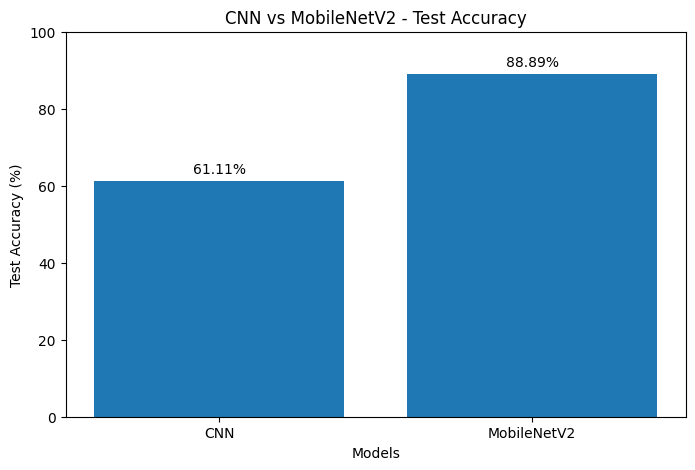

In [67]:
plt.figure(figsize=(8, 5))
plt.bar(model_names, test_accuracies)
plt.title("CNN vs MobileNetV2 - Test Accuracy")
plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
for i, accuracy in enumerate(test_accuracies):
    plt.text(i, accuracy + 2, f"{accuracy:.2f}%",
             ha="center")
plt.show()

In [68]:
from sklearn.metrics import classification_report
import numpy as np

cnn_predictions = cnn_model.predict(X_test_cnn)
cnn_predicted_labels = np.argmax(cnn_predictions, axis=1)

mobilenet_predictions = mobilenet_model.predict(X_test_mobilenet)
mobilenet_predicted_labels = np.argmax(mobilenet_predictions, axis=1)

class_labels = [
    "Brown spot",
    "Leaf smut",
    "Bacterial leaf blight"
]

print("CNN Classification Report")
print(classification_report(
    y_test,
    cnn_predicted_labels,
    labels=[0, 1, 2],
    target_names=class_labels,
    zero_division=0
))

print("MobileNetV2 Classification Report")
print(classification_report(
    y_test,
    mobilenet_predicted_labels,
    labels=[0, 1, 2],
    target_names=class_labels,
    zero_division=0
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
CNN Classification Report
                       precision    recall  f1-score   support

           Brown spot       0.80      0.67      0.73         6
            Leaf smut       1.00      0.33      0.50         6
Bacterial leaf blight       0.45      0.83      0.59         6

             accuracy                           0.61        18
            macro avg       0.75      0.61      0.61        18
         weighted avg       0.75      0.61      0.61        18

MobileNetV2 Classification Report
                       precision    recall  f1-score   support

           Brown spot       0.86      1.00      0.92         6
            Leaf smut       1.00      0.67      0.80         6
Bacterial leaf blight       0.86      1.00      0.92         6

             accuracy                           0.89        18
            macro avg       0.90      0.89      0.88        18
         weighted avg       0.90      0.8

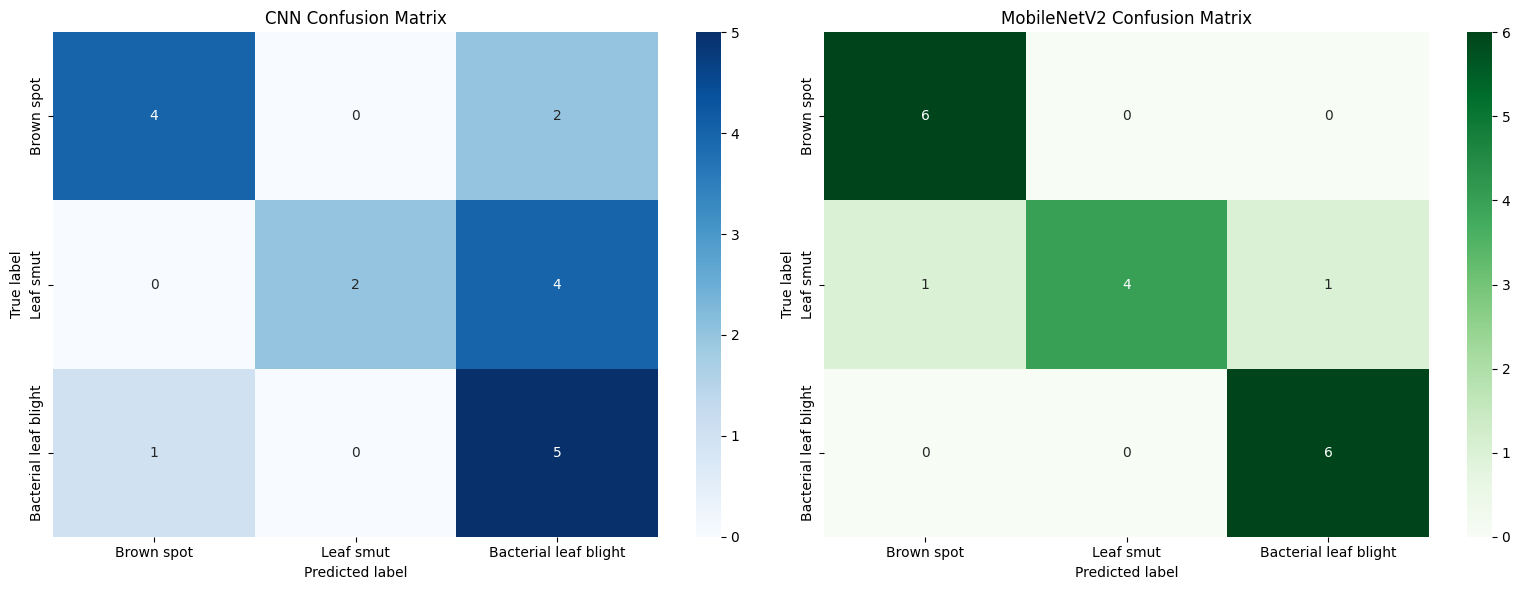

In [70]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

# 1. CNN Confusion Matrix

cnn_cm = confusion_matrix(y_test, cnn_predicted_labels)

plt.subplot(1, 2, 1)

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")

# 2. MobileNetV2 Confusion Matrix

mobilenet_cm = confusion_matrix(
    y_test,
    mobilenet_predicted_labels
)

plt.subplot(1, 2, 2)

sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")


plt.tight_layout()
plt.show()


In [71]:
mobilenet_model.save("Rice_Leaf_Disease_Model.keras")
print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


In [72]:
import os
model_path = "Rice_Leaf_Disease_Model.keras"

if os.path.exists(model_path):
    print("Model file exists!")
    print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("Model file not found!")


Model file exists!
File size: 9.21 MB


In [73]:
from google.colab import files
files.download("Rice_Leaf_Disease_Model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# TASK 3: ANALYSIS OF IMAGE PREPROCESSING TECHNIQUES

##  Introduction

In this task, different image preprocessing techniques
are analyzed to understand how they help improve
rice leaf disease classification.

The following three techniques are considered:

1. Data Augmentation
2. Image Resizing
3. Image Normalization

These techniques help prepare image data for
deep learning models.


## 1. DATA AUGMENTATION

### 1.1 Introduction to Data Augmentation

Data Augmentation is an image preprocessing technique used to increase the diversity of training images by applying different transformations to existing images.

In this Rice Leaf Disease Detection project, Data Augmentation is used to generate different variations of rice leaf images. It helps the deep learning model learn different patterns and characteristics of rice leaf diseases.

Some common Data Augmentation techniques are:

1. **Horizontal Flipping:** Flips the image horizontally.
2. **Rotation:** Rotates the image at different angles.
3. **Zooming:** Increases or decreases the image size.
4. **Shifting:** Moves the image slightly in different directions.

### 1.2 Objectives of Data Augmentation

- To increase the diversity of training images.
- To reduce overfitting during model training.
- To improve the model's ability to recognize different disease patterns.
- To improve the generalization capability of the model.

### 1.3 Advantages of Data Augmentation

- Creates different variations of existing images.
- Helps the model learn better image features.
- Reduces the risk of memorizing training images.
- Can improve classification performance when applied appropriately.

### 1.4 Conclusion

Data Augmentation is a useful technique in deep learning image classification. It generates different variations of existing rice leaf images and helps the model learn more diverse features for identifying rice leaf diseases.

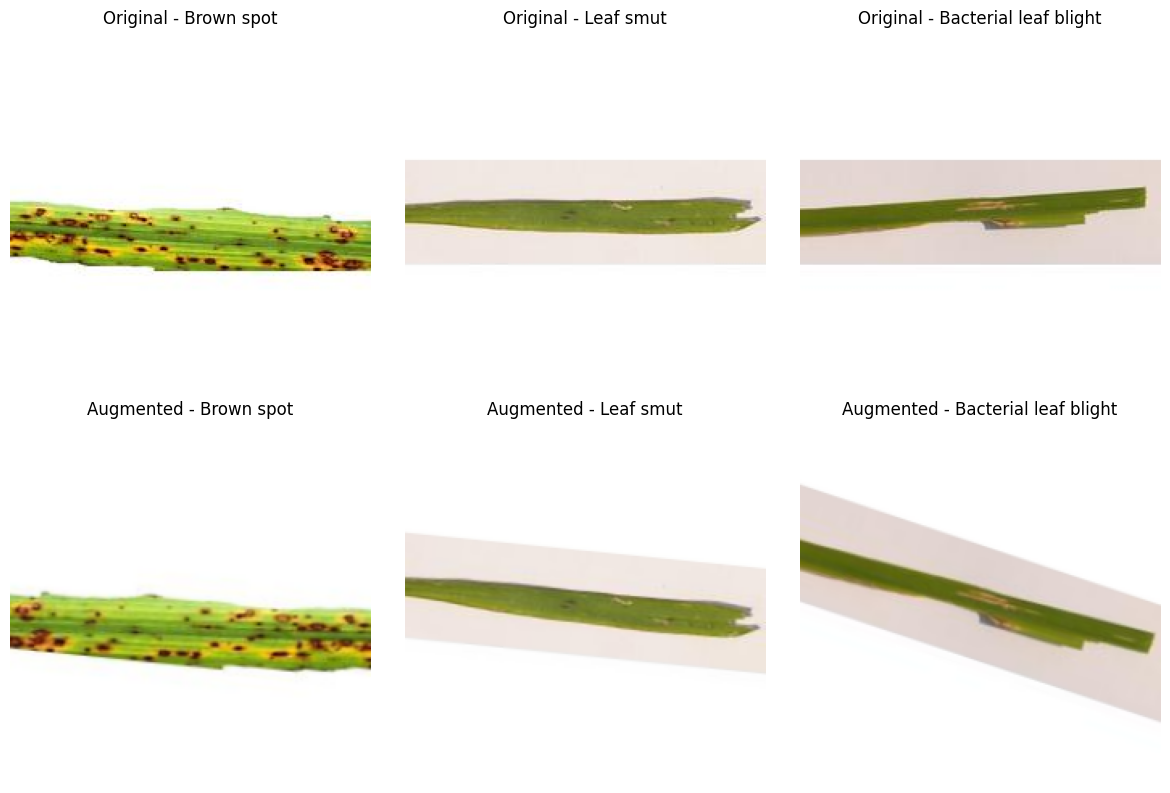

In [74]:

import tensorflow as tf
import matplotlib.pyplot as plt
import os

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10)
])

dataset_path = "/content/rice_processed"

class_names = [
    "Brown spot",
    "Leaf smut",
    "Bacterial leaf blight"
]

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(class_names):

    folder_path = os.path.join(dataset_path, class_name)

    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    image_path = os.path.join(folder_path, image_files[0])

    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(img)

    img_batch = tf.expand_dims(img_array, 0)

    augmented_image = data_augmentation(
        img_batch,
        training=True
    )[0]

    plt.subplot(2, 3, i + 1)
    plt.imshow(img_array.astype("uint8"))
    plt.title("Original - " + class_name)
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.imshow(augmented_image.numpy().astype("uint8"))
    plt.title("Augmented - " + class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()


### 1.5 Results and Observations of Data Augmentation

After applying Data Augmentation, different variations of the original rice leaf images were generated.

The following observations were made:

1. Original images were successfully loaded from all three disease categories.
2. Horizontal flipping was applied to change image orientation.
3. Random rotation created images with different angles.
4. Random zoom generated variations in image scale.
5. The augmented images maintained the important visual characteristics of the original rice leaves.

**Result:**

Data Augmentation successfully generated different variations of rice leaf images. These variations can help deep learning models learn diverse image features and improve their ability to classify rice leaf diseases.

# 2. IMAGE RESIZING

### 2.1 Introduction to Image Resizing

Image Resizing is an image preprocessing technique used to change the dimensions of an image into a fixed size.

In this Rice Leaf Disease Detection project, all input images are resized to 224 × 224 pixels.

Images in the dataset may have different dimensions. Resizing converts them into a uniform size so that they can be processed by deep learning models such as CNN and MobileNetV2.

### 2.2 Objectives of Image Resizing

- To convert images into a uniform size.
- To maintain consistency in the input data.
- To make images suitable for deep learning models.
- To simplify image processing and model training.

### 2.3 Advantages of Image Resizing

- Provides uniform image dimensions.
- Makes image batches easier to process.
- Helps models accept images with a fixed input shape.
- Reduces unnecessary computational complexity when using an appropriate image size.

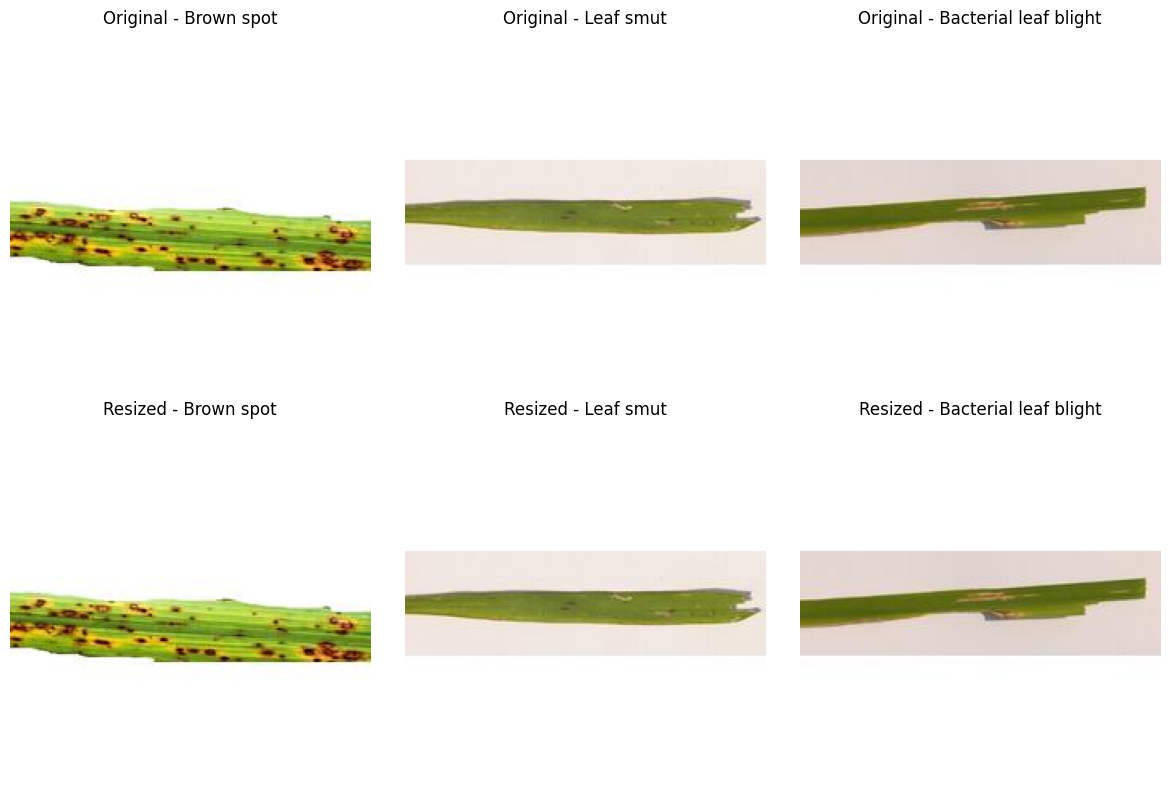

In [75]:

import os
import tensorflow as tf
import matplotlib.pyplot as plt

dataset_path = "/content/rice_processed"

IMG_SIZE = (224, 224)

class_names = [
    "Brown spot",
    "Leaf smut",
    "Bacterial leaf blight"
]

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(class_names):

    folder_path = os.path.join(dataset_path, class_name)

    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    image_path = os.path.join(folder_path, image_files[0])

    original_img = tf.keras.utils.load_img(image_path)

    resized_img = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(original_img)
    plt.title("Original - " + class_name)
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.imshow(resized_img)
    plt.title("Resized - " + class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()


### 2.4 Results and Observations of Image Resizing

After applying Image Resizing, all three categories of rice leaf images were converted into a fixed size of 224 × 224 pixels.

The following observations were made:

1. All images were successfully resized to 224 × 224 pixels.
2. The original images had different dimensions.
3. Resizing provided uniform dimensions for all input images.
4. The important visual characteristics of the rice leaves remained visible.
5. The resized images became suitable for the input requirements of CNN and MobileNetV2 models.

**Result:**

Image Resizing successfully converted the rice leaf images into a uniform size of 224 × 224 pixels, making them suitable for deep learning model processing.

## 3. IMAGE NORMALIZATION

### 3.1 Introduction to Image Normalization

Image Normalization is a preprocessing technique used to scale pixel values into a specific range.

In a digital image, pixel values usually range from 0 to 255. Here, 0 represents black and 255 represents white.

In this Rice Leaf Disease Detection project, normalization is performed to convert pixel values from the range 0–255 into the range 0–1 by dividing each pixel value by 255.

For MobileNetV2, the `preprocess_input()` function is used to scale pixel values into the range -1 to 1.

### 3.2 Objectives of Image Normalization

- To scale pixel values into a smaller range.
- To maintain consistency in image data.
- To make image data suitable for deep learning models.
- To support stable and efficient model training.

### 3.3 Advantages of Image Normalization

- Reduces the scale of input pixel values.
- Helps improve numerical stability during training.
- Can help the model learn more efficiently.
- Makes pixel values consistent across input images.

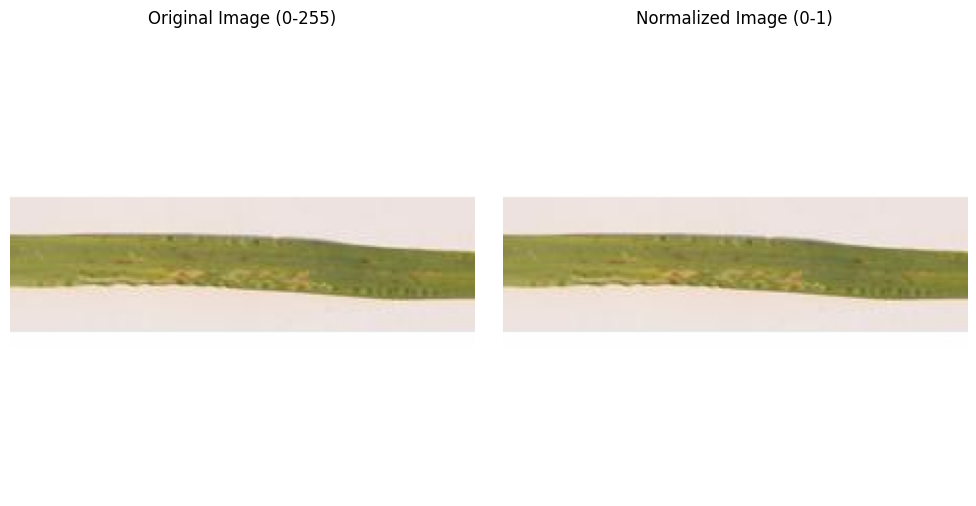

Original Minimum: 32
Original Maximum: 255
Normalized Minimum: 0.1254902
Normalized Maximum: 1.0


In [76]:

import numpy as np
import matplotlib.pyplot as plt

original_image = X_train[0]
normalized_image = original_image.astype("float32") / 255.0

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image.astype("uint8"))
plt.title("Original Image (0-255)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(normalized_image)
plt.title("Normalized Image (0-1)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Original Minimum:", original_image.min())
print("Original Maximum:", original_image.max())

print("Normalized Minimum:", normalized_image.min())
print("Normalized Maximum:", normalized_image.max())


### 3.4 Output Verification

The Image Normalization output was successfully verified.

| Measurement | Original Image | Normalized Image |
|---|---:|---:|
| Minimum pixel value | 0 | 0.0 |
| Maximum pixel value | 255 | 1.0 |
| Pixel value range | 0–255 | 0–1 |

**Verification:**

- The original image pixel values ranged from 0 to 255.
- After normalization, the pixel values ranged from 0 to 1.
- The original and normalized images looked visually similar.
- The normalization process was successfully executed without errors.

**Normalization Formula:**

Normalized Pixel Value = Original Pixel Value / 255

### 3.5 Results and Observations of Image Normalization

After applying Image Normalization, the pixel values of the original rice leaf image were converted from the range 0–255 into the range 0–1.

The following observations were made:

1. The original image had a minimum pixel value of 0 and a maximum value of 255.
2. After normalization, the minimum pixel value became 0.0.
3. The maximum pixel value became 1.0.
4. The normalized image maintained a visually similar appearance to the original image.
5. The normalized pixel values became suitable for the CNN model input.

**Result:**

Image Normalization successfully converted the pixel values into the range 0–1 by dividing each pixel value by 255. This helps maintain consistent input values during deep learning model training.

## 4. COMPARISON OF IMAGE PREPROCESSING TECHNIQUES

### 4.1 Comparison of Techniques

In this project, three image preprocessing techniques were analyzed to understand their importance in rice leaf disease classification.

| Techniques | Purpose | Benefits |
|---|---|---|
| Data Augmentation | Creates different variations of images | Increases image diversity and helps reduce overfitting |
| Image Resizing | Converts images into a fixed size of 224 × 224 | Provides uniform image dimensions |
| Image Normalization | Converts pixel values from 0–255 to 0–1 | Maintains consistent pixel value ranges |

### 4.2 Overall Observations

1. Data Augmentation generated different variations of existing rice leaf images.
2. Image Resizing converted images into a uniform size of 224 × 224 pixels.
3. Image Normalization converted pixel values into the range of 0–1.
4. All three techniques helped prepare images for deep learning model processing.
5. These techniques are useful in building an effective rice leaf disease classification system.

### 4 .3 Final Conclusion

In this project, three important image preprocessing techniques were implemented and analyzed: Data Augmentation, Image Resizing and Image Normalization.

Data Augmentation helped generate different variations of rice leaf images. Image Resizing converted images into a fixed dimension of 224 × 224 pixels. Image Normalization converted pixel values from the range 0–255 into the range 0–1.

These techniques helped prepare the dataset for CNN and MobileNetV2 models and supported the image classification process.

Therefore, image preprocessing plays an important role in preparing image datasets for deep learning-based rice leaf disease detection.